# 01 — Exploration annuelle : surfaces d'ulves, débits, nitrates, météo

Une ligne par baie et par année (2002-2022), construite par `python scripts/ingest.py`
(voir `data/README.md`). La cible est la **surface cumulée d'échouage** mesurée par le CEVA
lors de ses survols (mai, juillet, septembre), sommée sur les sites de chaque baie.

Questions :
1. Combien d'années exploitables a-t-on par baie ? C'est ce qui dit si une prévision est réaliste.
2. Comment évoluent les surfaces, et collent-elles aux volumes ramassés par les communes ?
3. Les débits, les nitrates et le flux d'azote de mai à août sont-ils liés à la surface ?

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RACINE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RACINE / "src"))
chemin = RACINE / "data" / "processed" / "baies_annuel.csv"
if chemin.exists():
    t = pd.read_csv(chemin)
else:  # reconstruit la table depuis le cache (ou télécharge, ~2 min la première fois)
    from algathon.series_annuelles import table_annuelle
    t = table_annuelle()
pd.set_option("display.precision", 2)
baies = sorted(t["baie"].unique())
print(len(t), "lignes,", len(baies), "baies,", t["annee"].min(), "-", t["annee"].max())

147 lignes, 7 baies, 2002 - 2022


## 1. Nombre de points disponibles par baie

In [2]:
def n(g, cols):
    return int(g.dropna(subset=cols).shape[0])

points = pd.DataFrame({
    b: {
        "surface": n(g, ["surface_ha"]),
        "surface + N-1": n(g, ["surface_ha", "surface_n_1"]),
        "+ flux jan-avr": n(g, ["surface_ha", "surface_n_1", "flux_n_jan_avr_t"]),
        "+ flux mai-août": n(g, ["surface_ha", "surface_n_1", "flux_n_mai_aout_t"]),
        "volume ramassé": n(g, ["volume_m3"]),
    } for b, g in t.groupby("baie")
}).T
points.loc["TOTAL"] = points.sum()
points

,surface,surface + N-1,+ flux jan-avr,+ flux mai-août,volume ramassé
concarneau_la_foret,20,18,15,14,21
douarnenez,19,17,6,6,19
fresnaye,15,12,6,6,10
guisseny,21,20,13,14,21
horn_guillec,21,20,17,17,12
lieue_de_greve,21,20,20,20,13
saint_brieuc,21,20,18,18,21
TOTAL,138,127,95,95,117


Environ 20 années par baie pour la surface, mais seulement **7 à 20 années complètes** dès qu'on
exige le flux d'azote (Douarnenez : débit du Kerharo mesuré depuis 2013 seulement ; Fresnaye : depuis 2010).
Avec si peu de points, un modèle par baie n'est pas réaliste : on entraîne un seul modèle commun
à toutes les baies, avec un niveau propre à chacune.

## 2. Surfaces d'échouage et volumes ramassés

Text(0.5, 1.01, "Surface cumulée d'échouage (CEVA) et volumes ramassés (communes)")

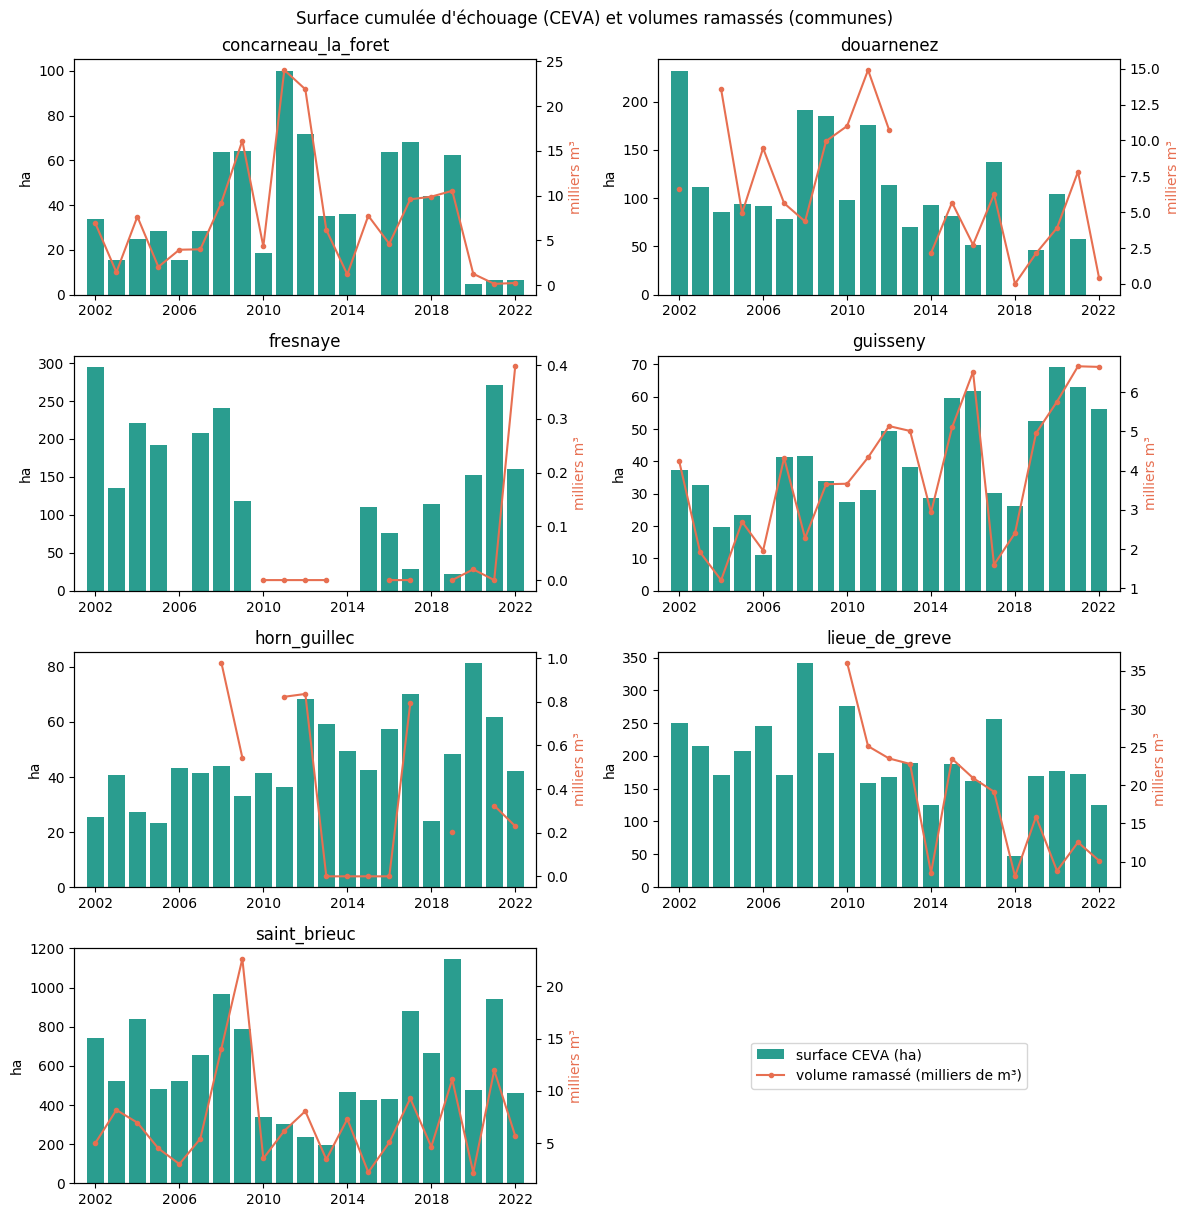

In [3]:
fig, axes = plt.subplots(4, 2, figsize=(12, 12))
for ax, b in zip(axes.flat, baies):
    g = t[t["baie"] == b]
    ax.bar(g["annee"].values, g["surface_ha"].values, color="#2a9d8f", label="surface CEVA (ha)")
    ax.set_title(b)
    ax.set_ylabel("ha")
    ax.set_xlim(2001, 2023)
    ax.set_xticks(range(2002, 2023, 4))
    ax2 = ax.twinx()
    ax2.set_xlim(2001, 2023)
    ax2.plot(g["annee"].values, g["volume_m3"].values / 1000, color="#e76f51", marker="o", ms=3,
             label="volume ramassé (milliers de m³)")
    ax2.set_ylabel("milliers m³", color="#e76f51")
axes.flat[-1].axis("off")
h1, l1 = axes.flat[0].get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
axes.flat[-1].legend(h1 + h2, l1 + l2, loc="center")
fig.tight_layout()
fig.suptitle("Surface cumulée d'échouage (CEVA) et volumes ramassés (communes)", y=1.01)

## 3. Corrélations (Spearman) entre la surface et les variables, par baie

,surface_n_1,volume_m3,debit_jan_avr,no3_jan_avr,flux_n_jan_avr_t,debit_mai_aout,no3_mai_aout,flux_n_mai_aout_t,ray_mars_mai,temp_mars_mai,pluie_mars_mai
concarneau_la_foret,0.42,0.84,-0.15,0.32,-0.22,0.25,0.35,0.17,3.01e-03,0.10,1.64e-01
douarnenez,0.05,0.35,-0.11,-0.21,0.11,-0.07,0.18,-0.14,5.12e-01,0.40,3.51e-03
fresnaye,0.38,0.44,0.43,-0.50,0.57,0.21,0.14,0.36,8.57e-02,0.02,6.07e-02
guisseny,0.46,0.83,0.28,-0.43,-0.08,0.06,-0.47,-0.19,1.62e-01,0.19,-1.88e-01
horn_guillec,0.27,-0.01,0.28,-0.34,-0.07,0.12,-0.47,-0.17,2.18e-01,0.03,2.21e-02
lieue_de_greve,-0.13,0.51,-0.23,0.37,-0.10,-0.13,0.32,0.06,3.77e-02,-0.02,-1.61e-01
saint_brieuc,0.35,0.56,-0.03,0.07,-0.03,0.42,0.01,0.34,-2.51e-01,0.06,1.23e-01


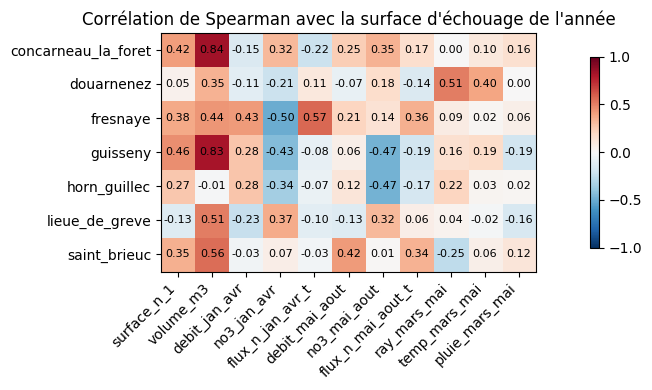

In [4]:
variables = ["surface_n_1", "volume_m3",
             "debit_jan_avr", "no3_jan_avr", "flux_n_jan_avr_t",
             "debit_mai_aout", "no3_mai_aout", "flux_n_mai_aout_t",
             "ray_mars_mai", "temp_mars_mai", "pluie_mars_mai"]
corr = pd.DataFrame({b: {v: g["surface_ha"].corr(g[v], method="spearman") for v in variables}
                     for b, g in t.groupby("baie")}).T
fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(variables))); ax.set_xticklabels(variables, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
ax.set_ylim(len(corr) - 0.5, -0.5)  # évite le rognage des lignes extrêmes (matplotlib 3.1)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        if not np.isnan(corr.values[i, j]):
            ax.text(j, i, "%.2f" % corr.values[i, j], ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Corrélation de Spearman avec la surface d'échouage de l'année")
fig.tight_layout()
corr

## 4. Flux d'azote de mai à août et surface

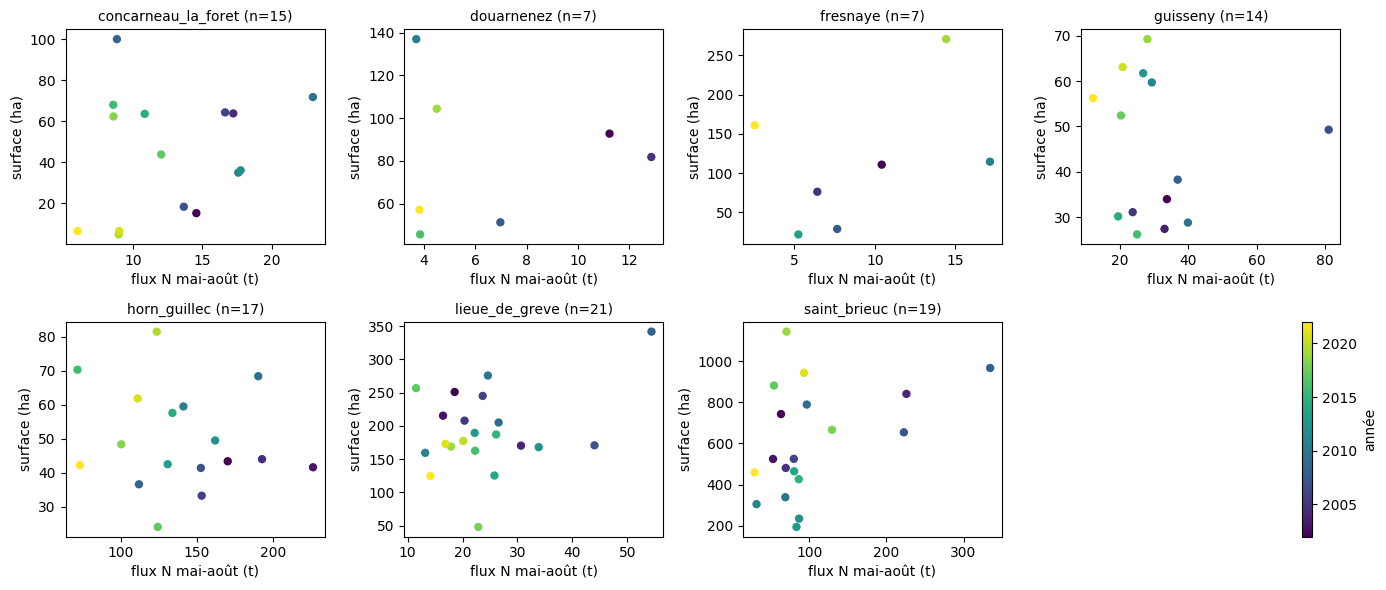

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, b in zip(axes.flat, baies):
    g = t[t["baie"] == b].dropna(subset=["flux_n_mai_aout_t", "surface_ha"])
    sc = ax.scatter(g["flux_n_mai_aout_t"].values, g["surface_ha"].values, c=g["annee"].values, cmap="viridis", s=25)
    ax.set_title("%s (n=%d)" % (b, len(g)), fontsize=10)
    ax.set_xlabel("flux N mai-août (t)")
    ax.set_ylabel("surface (ha)")
axes.flat[-1].axis("off")
fig.colorbar(sc, ax=axes.flat[-1], label="année")
fig.tight_layout()

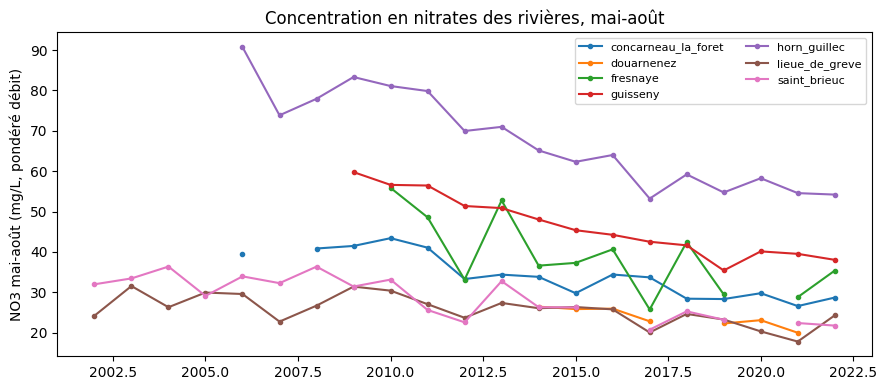

In [6]:
# Tendance des nitrates : explique les corrélations négatives NO3 / surface dans certaines baies
fig, ax = plt.subplots(figsize=(9, 4))
for b in baies:
    g = t[t["baie"] == b]
    ax.plot(g["annee"].values, g["no3_mai_aout"].values, marker=".", label=b)
ax.set_ylabel("NO3 mai-août (mg/L, pondéré débit)")
ax.legend(fontsize=8, ncol=2)
ax.set_title("Concentration en nitrates des rivières, mai-août")
fig.tight_layout()

## Ce qu'on retient

- **La cible CEVA est cohérente** : les volumes ramassés par les communes suivent la surface
  (Spearman 0,5 à 0,84 dans 6 baies sur 7 ; pas à Horn-Guillec, où l'on ramasse très peu).
- **Les liens avec les débits et les nitrates sont faibles à l'échelle annuelle**, et de signe variable.
  Le débit de mai à août est le plus parlant à Saint-Brieuc (0,42) et en Fresnaye (0,37).
  La forte corrélation négative NO3 jan-avr / surface en Fresnaye (-0,85) repose sur 11 années seulement.
- **Les nitrates baissent régulièrement depuis 2002** alors que les surfaces fluctuent : la corrélation
  brute NO3 / surface est donc dominée par la tendance (négative à Horn-Guillec et Guissény).
  Il faudra raisonner en écarts à la tendance, ou ajouter l'année comme variable.
- **Le stock de l'année précédente** est la variable la plus régulière (0,3 à 0,5 dans 5 baies sur 7).
- Avec 7 à 20 années complètes par baie, il faut s'attendre à un signal faible ;
  voir `scripts/baseline_annuel.py` pour les scores en validation temporelle.